# UL2ME007 – Algorithmics and Scientific Programming｜UL2ME007 – 算法与科学编程

# Course 3: Introduction to `Matplotlib`｜第 3 课：Matplotlib 入门

*This introduction draws on examples from an English-language computational physics course at École Polytechnique. Many thanks to its author, Michel Ferrero (CPHT, École Polytechnique), for permission to use and adapt them.*  
*本课参考了 École Polytechnique 计算物理课程中的英文示例，感谢课程作者 Michel Ferrero（CPHT, École Polytechnique）授权使用与改编。*

In this lesson, we turn numerical data into clear scientific figures. The sections build from one curve to complete, publication-ready plots.  
本课将学习如何把数值数据转化为清晰的科学图形，并从绘制一条曲线逐步过渡到结构完整、便于交流的图表。

### Course map｜课程导航

1. [Introduction: Matplotlib, `pyplot`, and display settings](#introduction)｜Matplotlib、`pyplot` 与显示设置  
2. [A first example](#section1)｜第一个绘图示例  
3. [Create a scientific graph](#section2)｜创建规范的科学图形  
4. [Shortcuts for markers, colours, and line styles](#section3)｜标记、颜色与线型的快捷写法  
5. [Subplots, semilog, and log-log plots](#section4)｜子图、半对数图与双对数图  
6. [Documentation and object-oriented plotting](#section5)｜文档与面向对象绘图  
7. [Integrated practice](#integrated-practice)｜综合练习  
8. [Summary and knowledge connection](#summary)｜总结与知识串联


## Learning guide｜学习指南

### What you will be able to do｜本课学习目标

By the end of the lesson, you should be able to:

- generate data with NumPy and plot one or more curves;
- distinguish a **figure** (the whole canvas) from an **Axes** (one plotting area);
- add titles, axis labels, units, legends, limits, ticks, and grids;
- control markers, colours, line styles, and line widths;
- arrange related graphs with subplots;
- choose linear, semilogarithmic, or log-log axes to reveal a relationship;
- read a Matplotlib example and adapt it to a new scientific problem.

完成本课后，你不仅要会“画出曲线”，还应能够区分图窗与坐标区，为图形添加标题、变量、单位和图例；能够通过子图组织比较，并根据指数关系或幂律关系选择合适的坐标尺度。最终目标是读懂一个 Matplotlib 示例，并把它迁移到新的科学问题中。

> Before running each cell, predict the result. Then change one parameter—such as the number of points, a line style, or an axis scale—and explain what changed and why.  
> 运行每个单元格前先预测结果，再尝试修改一个参数，例如采样点数、线型或坐标尺度，并解释图形为何发生变化。


<a id="introduction"></a>
## Introduction: Matplotlib, `pyplot`, and display settings｜引言：Matplotlib、`pyplot` 与显示设置

[`Matplotlib`](https://matplotlib.org/) is a Python library for creating high-quality static, animated, and interactive visualisations in many formats. Its gallery and documentation are especially useful when you want to discover a new type of plot.  
[`Matplotlib`](https://matplotlib.org/) 是 Python 中常用的可视化库，可以生成高质量的静态图、动态图和交互式图形。需要寻找新图形类型时，官方示例库与文档通常是最可靠的起点。

This lesson begins with `matplotlib.pyplot`, conventionally imported as `plt`. The `pyplot` interface keeps track of the current figure and Axes, so its commands are concise and well suited to short scripts and introductory work. Later in the lesson, we will also meet Matplotlib's object-oriented style, which gives finer control in larger programs.  
本课先使用通常简写为 `plt` 的 `matplotlib.pyplot`。它会自动管理当前图窗与坐标区，因此代码简洁，适合入门和短脚本；在课程后半部分，我们也会接触更适合大型程序的面向对象写法。

Import `pyplot` with the conventional alias below.  
首先按惯例导入 `pyplot`：


In [ ]:
import matplotlib.pyplot as plt


### Displaying figures in Spyder and Jupyter｜在 Spyder 与 Jupyter 中显示图形

Spyder can show figures either in its **Plots** pane or in separate interactive windows. For independent windows, open **Tools → Preferences → IPython Console → Graphics**, choose an automatic/interactive backend, and restart the IPython console if Spyder requests it. Menu names may differ slightly between versions.  
Spyder 可以把图形显示在 **Plots** 面板中，也可以使用独立的交互窗口。若希望缩放、平移或同时比较多个窗口，可在 **Tools → Preferences → IPython Console → Graphics** 中选择自动或交互式后端；若设置未立即生效，请重启 IPython Console。不同版本的菜单名称可能略有差异。

In a Jupyter notebook, figures normally appear below the code cell. These magic commands can change the display mode when needed:

```python
matplotlib inline   # static output inside the notebook｜在 notebook 内嵌静态图
%matplotlib auto     # choose an interactive backend automatically｜自动选择交互式后端
```

Run a magic command in its own code cell; it is an IPython instruction rather than ordinary Python syntax. For this notebook, the normal inline display is usually the clearest choice.  
魔法命令应单独放在代码单元格中运行；它属于 IPython 指令，而不是普通 Python 语法。学习本 notebook 时，默认的内嵌显示通常最清晰。


<a id="section1"></a>
## 1 — A first example｜1 — 第一个示例

The `pyplot` workflow is intuitive: prepare the horizontal coordinates, calculate the corresponding vertical values, create a figure, and plot `y` against `x`.  
`pyplot` 的基本流程很直观：先准备横坐标，再计算对应的纵坐标，随后创建图窗并按照 `x`—`y` 的顺序绘图。

The example below samples the cosine function on the interval $[0, 2\pi]$. Notice that NumPy creates and transforms the data, while Matplotlib displays it.  
下面在区间 $[0, 2\pi]$ 上对余弦函数进行采样。请留意两个库的分工：NumPy 负责生成和计算数据，Matplotlib 负责将数据可视化。


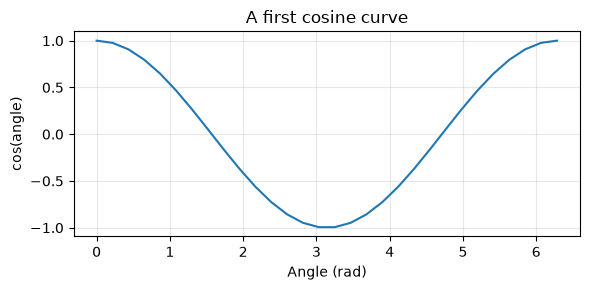

In [3]:
import numpy as np                 # Numerical arrays and mathematical functions (Course 2)
import matplotlib.pyplot as plt    # Scientific plotting

x_points = np.linspace(0, 2 * np.pi, 30)  # 30 angles from 0 to 2π
y_points = np.cos(x_points)                # Cosine at each angle

plt.figure(1, figsize=(6, 3))               # Create Figure 1
plt.plot(x_points, y_points)                # plot(horizontal, vertical)
plt.title("A first cosine curve")
plt.xlabel("Angle (rad)")
plt.ylabel("cos(angle)")
plt.grid(alpha=0.3)
plt.tight_layout()


A call to `plt.figure()` creates or activates a **figure**, similar to taking a blank sheet of paper. Subsequent plotting commands draw on its current Axes. If you call `plt.plot()` repeatedly without opening another figure, the curves are intentionally overlaid, which is useful for comparison.  
调用 `plt.figure()` 会创建或激活一个**图窗**，就像取出一张空白画纸；之后的绘图命令会作用于其中当前的坐标区。若不创建新图窗而多次调用 `plt.plot()`，曲线会叠加在同一坐标区中，这正适合比较数据。

Use `plt.close()` to close the current figure, `plt.close(1)` to close Figure 1, or `plt.close('all')` to close every figure. Numbered figures are convenient in a lesson, although larger programs often keep direct references such as `fig` and `ax`.  
可以用 `plt.close()` 关闭当前图窗，用 `plt.close(1)` 关闭编号为 1 的图窗，或用 `plt.close('all')` 关闭全部图窗。课程中使用编号便于观察；在更大的程序里，通常会把图窗和坐标区保存为 `fig`、`ax` 等变量。

<a id="section2"></a>
## 2 — Create a scientific graph｜2 — 创建规范的科学图形

Calling `plot` several times places several curves on the same Axes. A scientifically useful graph should do more than look attractive: it must identify the quantities, show units when applicable, distinguish curves clearly, and use readable scales. Titles, labels, legends, limits, ticks, and grids all help the reader interpret the data correctly.  
在同一坐标区中多次调用 `plot`，就能叠加多条曲线。科学图形不仅要美观，更要让读者准确理解数据：变量与单位应清楚，曲线应容易区分，坐标尺度应适合所研究的现象。标题、坐标标签、图例、范围、刻度和网格都服务于这一目标。

The following example compares sine and cosine and demonstrates the most common formatting commands.  
下面通过比较正弦与余弦，集中演示最常用的格式设置命令。


In [ ]:
x_points = np.linspace(0, 2 * np.pi, 30)
y1_points = np.cos(x_points)
y2_points = np.sin(x_points)

plt.figure(2, figsize=(8, 5))
# Explicit keywords describe colour, line style, width, marker, and legend label.
plt.plot(x_points, y1_points, color="blue", linestyle="-", linewidth=3,
         marker="o", label=r"$\cos(\theta)$")
plt.plot(x_points, y2_points, color="red", linestyle="--", linewidth=2,
         marker="x", label=r"$\sin(\theta)$")

plt.title("Sine and cosine", fontsize=20)
plt.xlabel(r"Angle $\theta$ (rad)", fontsize=16)
plt.ylabel("Function value", fontsize=16)
plt.legend(fontsize=14)
plt.tick_params(axis="both", labelsize=12)
plt.xlim(0, 2 * np.pi)
plt.ylim(-1.2, 1.2)
plt.grid(alpha=0.3)
plt.tight_layout()


<a id="section3"></a>
## 3 — Shortcuts for markers, colours, and line styles｜3 — 标记、颜色与线型的快捷写法

Explicit keywords such as `color='red'` are easy to read, but Matplotlib also accepts a compact format string. For example, `'-or'` combines a solid line (`-`), circle markers (`o`), and red (`r`). Either style is valid; prefer explicit keywords when clarity matters and compact strings for quick exploration.  
使用 `color='red'` 之类的完整关键字最容易阅读，不过 Matplotlib 也支持紧凑的格式字符串。例如 `'-or'` 同时表示实线（`-`）、圆形标记（`o`）和红色（`r`）。两种写法都正确：强调可读性时使用完整参数，快速试验时可使用缩写。


In [ ]:
x_points = np.linspace(0, 2 * np.pi, 30)
y_points = np.cos(x_points)

plt.figure(11, figsize=(7, 4))
# '-or' means: solid line (-), circle markers (o), red colour (r).
# 'lw=2' is the short form of 'linewidth=2'.
plt.plot(x_points, y_points, "-or", lw=2)
plt.title("Compact style notation: '-or'")
plt.xlabel("Angle (rad)")
plt.ylabel("cos(angle)")
plt.grid(alpha=0.3)
plt.tight_layout()


Many markers, line styles, and colours are available; the complete list appears in the [`plot` documentation](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.plot.html). The following set covers many everyday needs.  
Matplotlib 提供了大量标记、线型和颜色，完整列表可查阅 [`plot` 官方文档](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.plot.html)。下面这些选项已经能够覆盖许多常见场景：

- **Markers｜标记：** `.` point 点，`o` circle 圆点，`+` / `x` cross 十字，`^` / `v` / `<` / `>` triangle 三角形
- **Line styles｜线型：** `-` solid 实线，`--` dashed 虚线，`:` dotted 点线，`-.` dash-dot 点划线
- **Basic colours｜基本颜色：** `k` black 黑色，`b` blue 蓝色，`r` red 红色，`g` green 绿色

Do not rely on colour alone when curves may be printed in grayscale or viewed by someone with colour-vision deficiency. Combining colour with line style or markers makes the distinction more robust.  
如果图形可能以灰度打印，或需要照顾色觉差异，就不要只依赖颜色区分曲线；同时改变线型或标记会更可靠。


<a id="section4"></a>
## 4 — Subplots, semilog, and log-log plots｜4 — 子图、半对数图与双对数图

The preceding commands are enough for many figures. Three additional tools are especially useful in scientific work:

- `subplot` divides one figure into several plotting areas so related results can be compared;
- `semilogy` uses a logarithmic y-axis and is useful for exponential variation;
- `loglog` uses logarithmic scales on both axes and is useful for power laws.

前面的命令已经能完成许多绘图任务。科学计算中还经常需要三类工具：用 `subplot` 把一个图窗划分成多个坐标区，以便比较相关结果；用 `semilogy` 将纵轴改为对数尺度，从而观察指数变化；用 `loglog` 同时对两个坐标轴取对数，以识别幂律关系。

The next examples first define two oscillating functions with an exponentially increasing amplitude, then arrange them vertically and horizontally.  
下面先定义两个振幅随指数增大的振荡函数，再分别用上下排列和左右排列的子图展示它们。


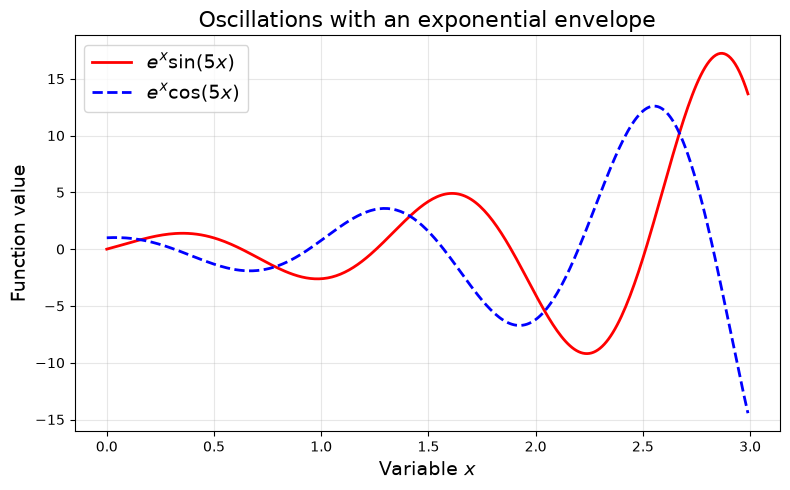

In [4]:
# Plot two oscillating functions with exponentially increasing amplitude.
FS = 14  # Shared font size: change it once to update the whole figure.

xr = np.arange(0, 3, 0.01)
yr1 = np.exp(xr) * np.sin(5 * xr)
yr2 = np.exp(xr) * np.cos(5 * xr)

plt.figure(3, figsize=(8, 5))
plt.plot(xr, yr1, "-r", lw=2, label=r"$e^x \sin(5x)$")
plt.plot(xr, yr2, "--b", lw=2, label=r"$e^x \cos(5x)$")
plt.title("Oscillations with an exponential envelope", fontsize=FS + 2)
plt.xlabel(r"Variable $x$", fontsize=FS)
plt.ylabel(r"Function value", fontsize=FS)
plt.legend(fontsize=FS)
plt.grid(alpha=0.3)
plt.tight_layout()


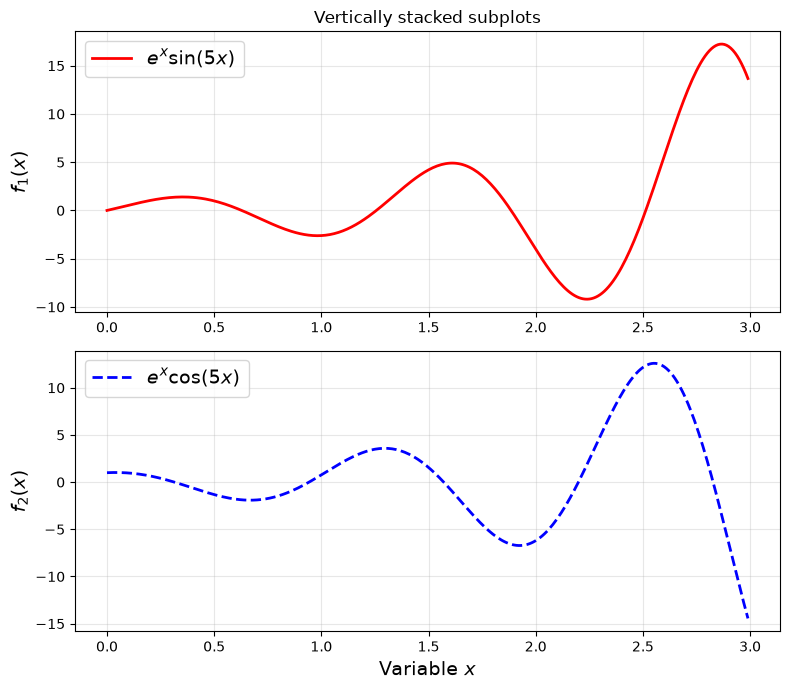

In [5]:
# Two vertically stacked subplots with a shared x-axis.
plt.figure(4, figsize=(8, 7))

plt.subplot(2, 1, 1)  # subplot(number of rows, number of columns, position)
plt.plot(xr, yr1, "-r", lw=2, label=r"$e^x \sin(5x)$")
plt.title("Vertically stacked subplots")
plt.ylabel(r"$f_1(x)$", fontsize=FS)
plt.legend(fontsize=FS)
plt.grid(alpha=0.3)

plt.subplot(2, 1, 2)
plt.plot(xr, yr2, "--b", lw=2, label=r"$e^x \cos(5x)$")
plt.xlabel(r"Variable $x$", fontsize=FS)
plt.ylabel(r"$f_2(x)$", fontsize=FS)
plt.legend(fontsize=FS)
plt.grid(alpha=0.3)

plt.tight_layout()


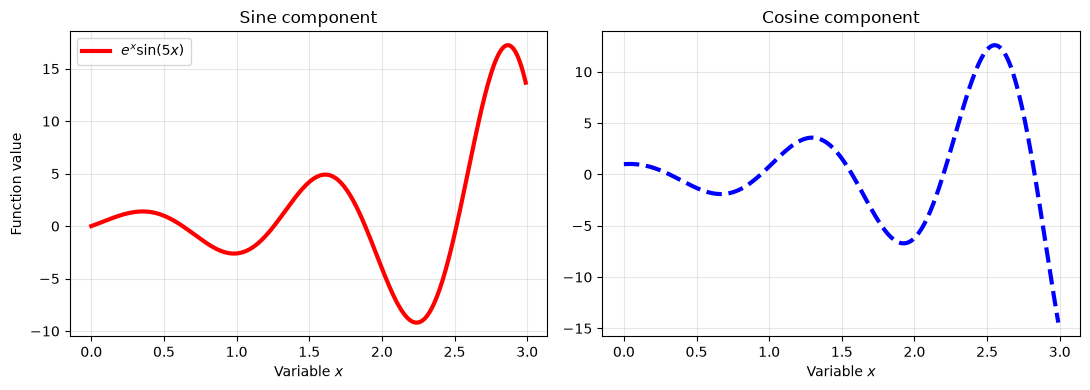

In [6]:
# Two side-by-side subplots.
plt.figure(5, figsize=(11, 4))

plt.subplot(1, 2, 1)  # one row, two columns, first position
plt.plot(xr, yr1, "-r", lw=3, label=r"$e^x \sin(5x)$")
plt.title("Sine component")
plt.xlabel(r"Variable $x$")
plt.ylabel(r"Function value")
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(xr, yr2, "--b", lw=3, label=r"$e^x \cos(5x)$")
plt.title("Cosine component")
plt.xlabel(r"Variable $x$")
# plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()


After all subplots have been defined, `plt.tight_layout()` automatically adjusts the spacing so that titles, labels, and tick text do not overlap. It is a small command with a large effect on readability.  
定义完所有子图后，调用 `plt.tight_layout()` 可以自动调整间距，避免标题、坐标标签和刻度文字相互遮挡。这条命令虽然简单，却能明显提升图形的可读性。


In [ ]:
# A semilog plot: x is linear and y is logarithmic.
yr3 = np.exp(2 * xr)

plt.figure(6, figsize=(7, 4))
plt.semilogy(xr, yr3, "-k", label=r"$e^{2x}$")
plt.title("Exponential function on a logarithmic y-axis")
plt.xlabel(r"Variable $x$", fontsize=14)
plt.ylabel(r"$e^{2x}$", fontsize=14)
plt.legend()
plt.grid(which="both", alpha=0.3)
plt.tight_layout()


In [ ]:
# A log-log plot: both x and y are logarithmic.
# Logarithmic axes require positive values, so x = 0 is excluded.
x_log = xr[xr > 0]
y_log = x_log**3

plt.figure(7, figsize=(7, 4))
plt.loglog(x_log, y_log, "-k", label=r"$x^3$")
plt.title("Power law on logarithmic axes")
plt.xlabel(r"Variable $x$", fontsize=14)
plt.ylabel(r"$x^3$", fontsize=14)
plt.legend()
plt.grid(which="both", alpha=0.3)
plt.tight_layout()


<a id="section5"></a>
## 5 — Documentation and object-oriented plotting｜5 — 文档与面向对象绘图

Matplotlib can produce far more plot types than we can cover here. A productive strategy is to find a relevant example in the official gallery, understand the important lines, and adapt them to your own data. Copying code without checking the data shape, units, and chosen scale often produces a graph that runs but communicates the wrong idea.  
Matplotlib 能绘制的图形远多于本课示例。高效的学习方法是从官方示例库中找到相近案例，读懂关键语句，再根据自己的数据进行调整。直接复制代码而不检查数据形状、单位和坐标尺度，往往会得到“可以运行但表达错误”的图形。

So far we have used the state-based `pyplot` style. The object-oriented style explicitly creates a figure and an Axes:

```python
fig, ax = plt.subplots()
ax.plot(x_points, y_points)
ax.set_xlabel("Angle (rad)")
```

到目前为止，我们主要使用由 `pyplot` 管理当前图形的写法。面向对象写法则显式创建 `fig` 与 `ax`，随后通过 `ax.plot()`、`ax.set_xlabel()` 等方法操作指定坐标区。它并不改变绘图原理，但在多子图或大型程序中更清晰，也不容易把命令作用到错误的坐标区。

Useful references｜推荐资料：

- [Pyplot tutorial](https://matplotlib.org/stable/tutorials/pyplot.html) — a concise introduction to the state-based interface｜`pyplot` 接口的简明教程
- [Quick start guide](https://matplotlib.org/stable/users/explain/quick_start.html) — including the object-oriented workflow｜包含面向对象流程的快速入门
- [Illustrative video](https://www.youtube.com/watch?v=O_OeWxpnUc0) — a discussion of Matplotlib's two interfaces｜介绍 Matplotlib 两种接口的视频


<a id="integrated-practice"></a>
## 6 — Integrated practice: a damped oscillator｜6 — 综合练习：阻尼振动

Let us connect the whole lesson with a simple mechanics model:

$$x(t) = A_0 e^{-\gamma t}\cos(2\pi f t).$$

Here $A_0$ is the initial amplitude, $\gamma$ the damping coefficient, and $f$ the frequency. NumPy will create the time samples and evaluate the model; Matplotlib will show the displacement together with the positive and negative exponential envelopes.  
现在用一个简单的力学模型串联本课内容：$A_0$ 表示初始振幅，$\gamma$ 是阻尼系数，$f$ 是频率。NumPy 负责生成时间序列并计算位移，Matplotlib 则同时展示振动曲线与上下包络线。

Before running the cell, predict the value at $t=0$, the long-term behaviour, and what happens when either $f$ or $\gamma$ increases. Then inspect how the code handles data, styles, labels, units, limits, legend, grid, and layout in one coherent workflow.  
运行前先预测 $t=0$ 时的位移、长时间后的变化趋势，以及增大 $f$ 或 $\gamma$ 会产生什么影响；再观察代码如何在同一流程中组织数据、样式、变量、单位、范围、图例、网格与版面。


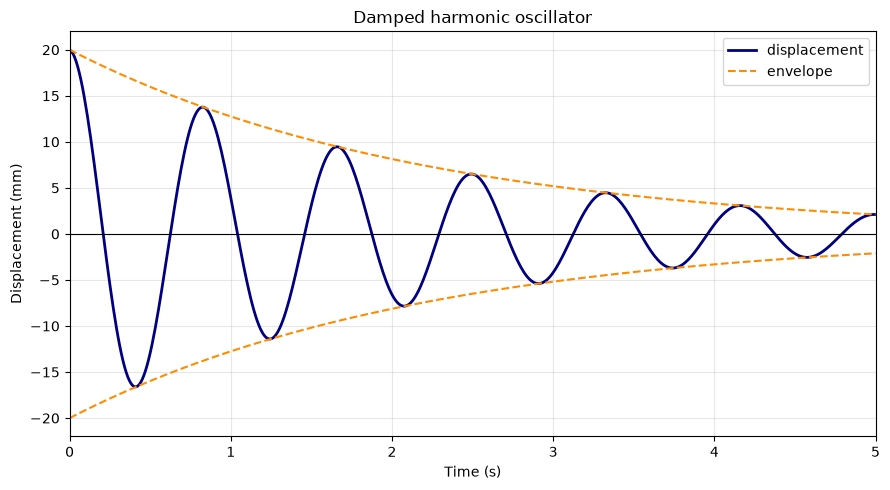

In [7]:
# Model parameters
A0_mm = 20.0        # initial amplitude in millimetres
gamma_per_s = 0.45  # damping coefficient in s⁻¹
frequency_hz = 1.2  # oscillation frequency in Hz

# 1. Generate and calculate the data with NumPy.
time_s = np.linspace(0, 5, 500)
envelope_mm = A0_mm * np.exp(-gamma_per_s * time_s)
displacement_mm = envelope_mm * np.cos(2 * np.pi * frequency_hz * time_s)

# 2. Create the figure and plot the model.
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(time_s, displacement_mm, color="navy", lw=2, label="displacement")
ax.plot(time_s, envelope_mm, "--", color="darkorange", label="envelope")
ax.plot(time_s, -envelope_mm, "--", color="darkorange")
ax.axhline(0, color="black", lw=0.8)

# 3. Make the scientific meaning explicit.
ax.set_title("Damped harmonic oscillator")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Displacement (mm)")
ax.set_xlim(time_s[0], time_s[-1])
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()

# Optional export for a report:
# fig.savefig("C3_damped_oscillator.png", dpi=150, bbox_inches="tight")


<a id="summary"></a>
## Summary and knowledge connection｜总结与知识串联

A clear scientific figure follows a complete reasoning chain:

**scientific question → numerical model → NumPy arrays → choice of scale → Matplotlib figure → labels and visual encoding → interpretation**

一幅清晰的科学图形来自一条完整的思考链：先提出科学问题，把规律写成数值模型，用 NumPy 生成数组；再根据数据关系选择线性、半对数或双对数尺度，用 Matplotlib 组织图窗和坐标区；最后通过变量名、单位、图例、线型与网格帮助读者解释结果。

In the first example, NumPy supplied samples of a cosine function and Matplotlib displayed them. We then added the elements required in a scientific graph, used style shortcuts, arranged related results in subplots, and selected logarithmic axes for exponential and power-law relationships. The final damped-oscillation example brings the whole workflow together and connects this lesson to mechanics.  
从第一个余弦示例开始，我们让 NumPy 提供数据、Matplotlib 呈现数据；随后补全科学图形所需的信息，学习样式快捷写法与子图布局，并根据指数关系和幂律关系选择对数坐标。最后的阻尼振动示例把这些能力串联起来，也让绘图重新回到力学问题中。

### A reusable plotting checklist｜可复用的绘图检查表

1. **Data:** Are `x` and `y` compatible arrays, and are the values physically meaningful?  
   **数据：** `x` 与 `y` 的形状是否匹配，数值是否符合物理意义？
2. **Structure:** Should curves be overlaid or separated into subplots?  
   **结构：** 曲线应叠加比较，还是拆分成多个子图？
3. **Scale:** Does a linear, semilog, or log-log axis best reveal the relationship?  
   **尺度：** 线性、半对数还是双对数坐标最能揭示关系？
4. **Communication:** Are title, variable names, units, legend, and styles unambiguous?  
   **表达：** 标题、变量、单位、图例与线型是否清楚无歧义？
5. **Verification:** Does the curve agree with limiting cases and your prediction?  
   **验证：** 图形是否符合边界情况和运行前的预测？

### Self-check｜自我检查

- Can I explain the difference between a figure and an Axes?  
  我能否解释 figure 与 Axes 的区别？
- Can I predict the graph before running the code and justify the selected scale?  
  我能否在运行前预测图形，并说明为何选择这种坐标尺度？
- Can I modify the integrated example for a different frequency, damping coefficient, or initial amplitude?  
  我能否修改综合示例中的频率、阻尼系数或初始振幅？
- Can I produce a figure that another person can understand without reading my code?  
  我能否画出一幅无需查看代码也能被他人准确理解的图？
